In [1]:
import pandas as pd

Extract from data sources 
flat files
    read_csv()
    read_json()
    read_parquet()
Databases - pd.read_sql() + sqlalchemy
API - Web based resources

In [4]:
sales_df = pd.read_csv("C:/Users/Artophilic/Analysis Projects/ETL/Spring Skillup/LA_Retail_Sales.csv")

sales_df.head()

,store_id,store_name,product_category,date,Unit sales,DOLLAR SALES,store_zip,promotion_flag
0,LA002,Store_2,Household,9/1/24,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,9/1/24,14.0,86.63,90004,True
2,LA004,Store_4,Produce,9/15/24,18.0,298.26,90003,True
3,LA003,Store_3,Household,9/7/24,7.0,25.69,90001,True
4,LA008,Store_8,Beverages,9/18/24,25.0,85.46,90005,False


In [5]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          750 non-null    object 
 1   store_name        750 non-null    object 
 2   product_category  750 non-null    object 
 3   date              750 non-null    object 
 4   Unit sales        745 non-null    float64
 5   DOLLAR SALES      743 non-null    float64
 6   store_zip         750 non-null    object 
 7   promotion_flag    750 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 41.9+ KB


In [ ]:
import glob

file_paths = glob.glob(r"C:\Users\Artophilic\Analysis Projects\ETL\Spring Skillup\LA_Retail_Sales_By_Day\*.csv")

print(file_paths)

sales_df_2 = pd.concat([pd.read_csv(i) for i in file_paths], ignore_index=True)

sales_df_2.info()

'''
pd.concat(objs, axis=0, join="outer", ignore_index=False, keys=None)

Objs - a list (or other iterable) of DataFrames/Series. The first argument is a collection, 
not two separate arguments. pd.concat(a, b) is wrong; pd.concat([a, b]) is right.

axis

axis=0 (default): stack vertically, adding rows. Use this when files have the same columns, like monthly sales files.
axis=1: place side by side, adding columns, aligned on the index.

join: what to do with columns (or the index, for axis=1) that don’t appear in every object.

"outer" (default): keep everything, fill gaps with NaN.
"inner": keep only the columns common to all.

4. ignore_index: each DataFrame brings its own index (0, 1, 2...). Without this, you get duplicate index labels after stacking. 
ignore_index=True discards the old indexes and renumbers 0 to n-1.
'''

['C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-01.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-02.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-03.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-04.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-05.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-06.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-07.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-08.csv', 'C:\\Users\\Artophilic\\Analysis Projects\\ETL\\Spring Skillup\\LA_Retail_Sales_By_Day\\sales_2024-09-09.csv', 

In [21]:
#Creating dataframes for each day

sales_df_day_wise = pd.DataFrame()

for day in range(1,6):
    print(day)
    day_df = pd.read_csv(f"C:/Users/Artophilic/Analysis Projects/ETL/Spring Skillup/LA_Retail_Sales_By_Day/sales_2024-09-{day:02d}.csv")
    sales_df_day_wise = pd.concat([sales_df_day_wise, day_df], ignore_index=True)
    print(len(sales_df_day_wise))

sales_df_day_wise.head()


1
30
2
57
3
81
4
97
5
120


,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA008,Store_8,Produce,2024-09-01,4.0,79.99,90001,False
3,LA010,Store_10,Beverages,2024-09-01,22.0,140.45,90005,True
4,LA006,Store_6,Snacks,2024-09-01,17.0,50.03,90003,False


In [22]:
sales_df_day_wise.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          120 non-null    object 
 1   store_name        120 non-null    object 
 2   product_category  120 non-null    object 
 3   date              120 non-null    object 
 4   unit_sales        120 non-null    float64
 5   dollar_sales      120 non-null    float64
 6   store_zip         120 non-null    object 
 7   promotion_flag    120 non-null    bool   
dtypes: bool(1), float64(2), object(5)
memory usage: 6.8+ KB


In [ ]:
#Reading JSON file

sales_df_by_json = pd.read_json("C:/Users/Artophilic/Analysis Projects/ETL/Spring Skillup/LA_Retail_Sales.json", lines=True)
'''
If the JSON file is in a single line, you can use the default pd.read_json() function.
If the JSON file is in multiple lines, you can use the pd.read_json() function with the lines=True parameter.'''

'\nIf the JSON file is in a single line, you can use the default pd.read_json() function.\nIf the JSON file is in multiple lines, you can use the pd.read_json() function with the lines=True parameter.'

In [25]:
sales_df_by_json.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA004,Store_4,Produce,2024-09-15,18.0,298.26,90003,True
3,LA003,Store_3,Household,2024-09-07,7.0,25.69,90001,True
4,LA008,Store_8,Beverages,2024-09-18,25.0,85.46,90005,False


In [26]:
#Reading parquet file

sales_df_by_parquet = pd.read_parquet("C:/Users/Artophilic/Analysis Projects/ETL/Spring Skillup/LA_Retail_Sales.parquet")

sales_df_by_parquet.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag
0,LA002,Store_2,Household,2024-09-01,16.0,96.28,90004,True
1,LA001,Store_1,Beverages,2024-09-01,14.0,86.63,90004,True
2,LA004,Store_4,Produce,2024-09-15,18.0,298.26,90003,True
3,LA003,Store_3,Household,2024-09-07,7.0,25.69,90001,True
4,LA008,Store_8,Beverages,2024-09-18,25.0,85.46,90005,False


In [27]:
#Extract using SQL

import sqlite3

conn = sqlite3.connect("C:/Users/Artophilic/Analysis Projects/ETL/Spring Skillup/la_sales.sqlite")

In [28]:
sales_df_by_sql = pd.read_sql("SELECT * FROM sales", con = conn)

In [29]:
sales_df_by_sql.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag,rev_per_unit,temp
0,LA002,Store_2,Household,2024-09-01 00:00:00,16,96.28,90004,1,6.02,71.19
1,LA001,Store_1,Beverages,2024-09-01 00:00:00,14,86.63,90004,1,6.19,71.19
2,LA004,Store_4,Produce,2024-09-15 00:00:00,18,298.26,90003,1,16.57,63.91
3,LA003,Store_3,Household,2024-09-07 00:00:00,7,25.69,90001,1,3.67,78.37
4,LA008,Store_8,Beverages,2024-09-18 00:00:00,25,85.46,90005,0,3.42,60.82


In [30]:
sales_df_Beverages = pd.read_sql('''
    SELECT * 
    FROM sales
    WHERE product_category = 'Beverages'
''', con = conn)

sales_df_Beverages.head()

,store_id,store_name,product_category,date,unit_sales,dollar_sales,store_zip,promotion_flag,rev_per_unit,temp
0,LA001,Store_1,Beverages,2024-09-01 00:00:00,14,86.63,90004,1,6.19,71.19
1,LA008,Store_8,Beverages,2024-09-18 00:00:00,25,85.46,90005,0,3.42,60.82
2,LA004,Store_4,Beverages,2024-09-23 00:00:00,3,41.71,90004,0,13.90,67.08
3,LA009,Store_9,Beverages,2024-09-16 00:00:00,49,139.56,90005,1,2.85,65.48
4,LA008,Store_8,Beverages,2024-09-28 00:00:00,44,605.54,90001,1,13.76,65.03


In [ ]:
#Dataframe for avarage unit sales by store_id

sales_df_avg_unit_sales_by_store = pd.read_sql('''
SELECT store_id, AVG(unit_sales) AS avg_unit_sales FROM sales GROUP BY store_id''', con = conn)

sales_df_avg_unit_sales_by_store.head()

,store_id,avg_unit_sales
0,LA001,25.447368
1,LA002,24.054054
2,LA003,25.487179
3,LA004,24.901639
4,LA005,27.000000


<Axes: title={'center': 'Average Unit Sales by Store ID'}, xlabel='store_id'>

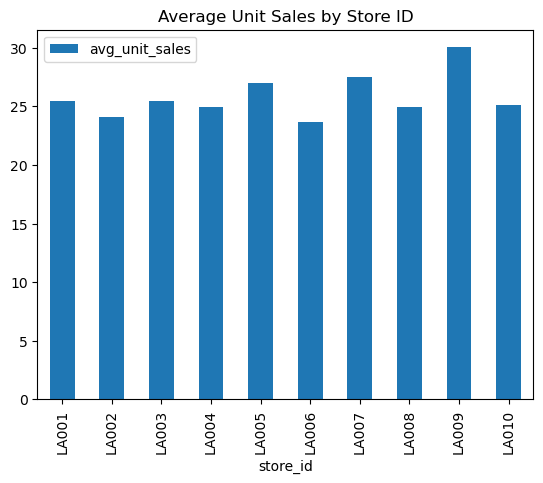

In [32]:
#Plotting a bar chart

pd.read_sql('''
SELECT store_id, AVG(unit_sales) AS avg_unit_sales FROM sales GROUP BY store_id''', con = conn).plot.bar(x='store_id', y='avg_unit_sales', title='Average Unit Sales by Store ID')